# Lab 8: Monte Carlo Markov Chain (MCMC)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate


## **Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

### Punto 1

In [12]:
r = np.linspace(0,4, 20)
f = lambda x: np.pow(x,1/2)

In [118]:
def MC_integral(f, r, n):
    samples = np.random.uniform(r.min(),r.max(), size = n)
    rango = r.max() - r.min() 
    resultado = rango * np.mean(f(samples))
    print(resultado)
    return resultado

In [120]:
mc_1 = MC_integral(f,r,n=100)

5.583409264253322


In [76]:
analtica = integrate.quad(f, r.min(), r.max())[0]
print(analtica)

5.333333333333335


### Punto 2

In [147]:
f_2D = lambda y, x: x*y**(2)
rx = np.linspace(0, 2, 20)
ry = np.linspace(0, 1, 20)

In [148]:
def MC_integral_2D(f, rx, ry, n):
    x = np.random.uniform(rx.min(), rx.max(), size = n)
    y = np.random.uniform(ry.min(), ry.max(), size = n)
    area = (rx.max() - rx.min()) * (ry.max() - ry.min())
    resultado = area * np.mean(f(y,x))
    print(resultado)
    return resultado

In [156]:
mc_2 = MC_integral_2D(f_2D,rx,ry,n=100)

0.7038585206902427


In [150]:
analtica_2d = integrate.dblquad(f_2D, rx.min(), rx.max(), ry.min(), ry.max())[0]
print(analtica_2d)

0.6666666666666667


## **Exercise 2**: Read about the Ising's model 1D, 2D and 3D.

El modelo de Ising es un modelo matemático del ferromagnetismo en mecanica estadística. El modelo permite estudiar cómo de comportan los materiales magnéticos a dististintas temperaturas y sus transiciones de fases. Las variable independiente son los espines los cuales representan momentos dipolares atómicos y solo pueden tomar dos valores (+1 o -1), todo estos espines se organizan en una estructura (un grafo) organizados de forma periodica y iteractuan principalmente entre sus vecinos cercanos. 

El sistema modelado siempre tiende a estar a buscar el estado de menor energia, pero el calor peturba este orden permitiendo cambios de fase.

En 1D, el modelo resuelto en 1925 por Ernst Ising descubrio que no existe ninguna transición de fase ya que T > 0 el sistema se comporta siempre como un paramagnetico, de hecho, solo a t=0 (temperatura absoluta) el sistema se logra a ordenar completamente, es decir, solo presenta un punto critico únicamente a T = 0 K.

En 2D, fue resuelto por Larns Onsager en 1944, presenta una transición de fase a una temperatura critica  Tc (temperatura de Curie). Por encima de esta el sistema es paragmagnético, por debajo se ordena (ferromagnético).

En 3D, Tc > 0 las bajas temperaturas no son suficientes para destruir el orden magnético, T < Tc por debajo de la temperatura critica la iteracción entre espines favorece el orden magnético (fase ferromagnetico), T > Tc las flutuaciones térmicas destruyen el orden magnético (fase paramagnética).

Fuentes:

1) https://www.famaf.unc.edu.ar/~cannas/Notas_TermoII/Notas-TermoII-2010-12.pdf
2) https://en.wikipedia.org/wiki/Ising_model#cite_note-2

## **Exercise 3**: Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

### Punto 1

In [2]:
#*********** MKS units ************** 
# Vacuum permeability (H/m)
mu0 = 4*np.pi*1e-7 
# Boltzmann constant (J/K)
k = 1.380649e-23
# Bohr magneton (J/T)
muB = 9.2740100783e-24
# g factor for electron
g = 2.00231930436256
# magneton de Bhor under k (Kelvin/Tesla)
C = 0.6717098224 # C = k_B / mu_B 
# Constante de acoplamiento en Kelvin [K]
J = 2.5

print(f"Ratio of Bohr magneton to Boltzmann constant: {muB/k:.3e}\n")

Ratio of Bohr magneton to Boltzmann constant: 6.717e-01



In [3]:
n = 10
temperatura = [5, 10, 15]
campo = np.linspace(-30, 30, 61)
mc_steps = 100000

**Se elegi el spin de forma aleatoria**

In [ ]:
x = []

for t in temperatura:
    for c in campo:
        # Incializar los espines aleatoriamente
        spines = np.random.choice([-1, 1], size=(n, n))
        for step in range(mc_steps):
            # Se elige un espin al azar
            i = np.random.randint(0,n)
            j = np.random.randint(0,n)
            s = spines[i, j]
            # Se tiene en cuenta los primeros vecinos y el factor de acoplamiento
            vecinos = spines[(i + 1) % n, j] + spines[(i - 1) % n, j] + \
                        spines[i, (j + 1) % n] + spines[i, (j - 1) % n]
            deltae = 2 * spines[i, j] * (J * vecinos + c)
            if deltae <= 0 or np.random.rand() < np.exp(-deltae * C / t):
                spines[i, j] = -s
            
        Magpro = np.sum(spines) / (n * n)
        x.append([t,c, Magpro])

In [ ]:
x=np.asarray(x)
xd=pd.DataFrame(x,columns=['T','H','Magnetization'])

T1 = xd[xd['T'] == 5]
T2 = xd[xd['T'] == 10]
T3 = xd[xd['T'] == 15]

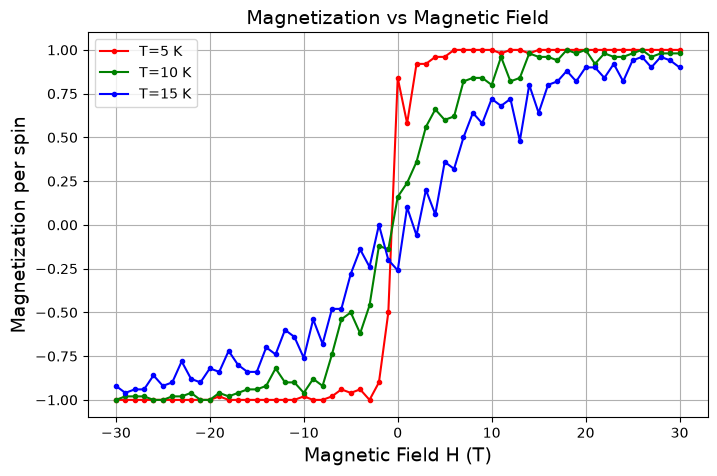

In [26]:
plt.figure(figsize=(8,5))
plt.plot(T1['H'], T1['Magnetization'],'r.-',label='T=5 K')
plt.plot(T2['H'], T2['Magnetization'],'g.-',label='T=10 K')
plt.plot(T3['H'], T3['Magnetization'],'b.-',label='T=15 K')
plt.xlabel('Magnetic Field H (T)',size=14)
plt.ylabel('Magnetization per spin',size=14)
plt.title('Magnetization vs Magnetic Field',size=14)
plt.legend(loc='best')
plt.grid()
plt.show()

**se recorre todos los espines**

In [8]:
n = 10
temperatura = [5, 10, 15]
campo = np.linspace(-30, 30, 61)
mc_steps = 100

In [9]:
x = []

for t in temperatura:
    for c in campo:
        spines = np.random.choice([-1, 1], size=(n, n))
        Mag = 0
        historia_spines = []
        for step in range(mc_steps):
            for i in range(n):
                for j in range(n):
                    s = spines[i, j]
                    vecinos = spines[(i + 1) % n, j] + spines[(i - 1) % n, j] + \
                            spines[i, (j + 1) % n] + spines[i, (j - 1) % n]
                    deltae = 2 * s * (J * vecinos + c)
                    if deltae <= 0 or np.random.rand() < np.exp(-deltae * C / t):
                          spines[i, j] = -s
                    Mag += spines[i, j]
        Magpro = Mag / (mc_steps * n * n)
        x.append([t,c, Magpro])

In [10]:
x=np.asarray(x)
xd=pd.DataFrame(x,columns=['T','H','Magnetization'])

T1_ = xd[xd['T'] == 5]
T2_ = xd[xd['T'] == 10]
T3_ = xd[xd['T'] == 15]

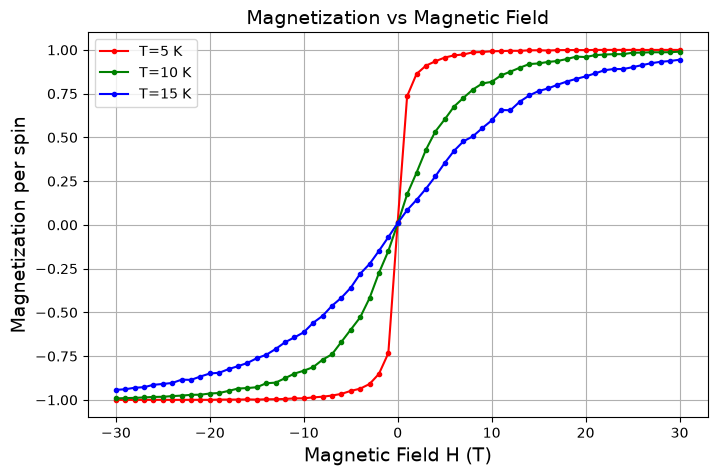

In [11]:
plt.figure(figsize=(8,5))
plt.plot(T1_['H'], T1_['Magnetization'],'r.-',label='T=5 K')
plt.plot(T2_['H'], T2_['Magnetization'],'g.-',label='T=10 K')
plt.plot(T3_['H'], T3_['Magnetization'],'b.-',label='T=15 K')
plt.xlabel('Magnetic Field H (T)',size=14)
plt.ylabel('Magnetization per spin',size=14)
plt.title('Magnetization vs Magnetic Field',size=14)
plt.legend(loc='best')
plt.grid()
plt.show()

### Punto 2

La comparacion analitica solo se puede para H = 0, pero utlizando la aproximación del campo medio se llega a una expresion de la magnetizacion para H distinto de 0

$$m = \tanh[\beta (q J m + B)] = \tanh\left( \frac{1}{k_B T} (q J m + \mu_B H) \right) = \tanh\left( \frac{q J m + \mu_B H}{k_B T} \right)$$

donde q = 4 número de vecinos  o de coordinación , J el acoplamiento, $B = \mu_B H$ la energia del campo magnético externo

In [32]:
def magnetizacion_curie_weiss(H_array, T, q):
    m_sol = []
    beta = 1.0 / T # Asumiendo k_B = 1
    for H in H_array:
        B = H / C 
        m = 0.5    # Valor inicial para iterar
        for _ in range(200):
            m = np.tanh(beta * (q * J * m + B))
        m_sol.append(m)
    return np.array(m_sol)

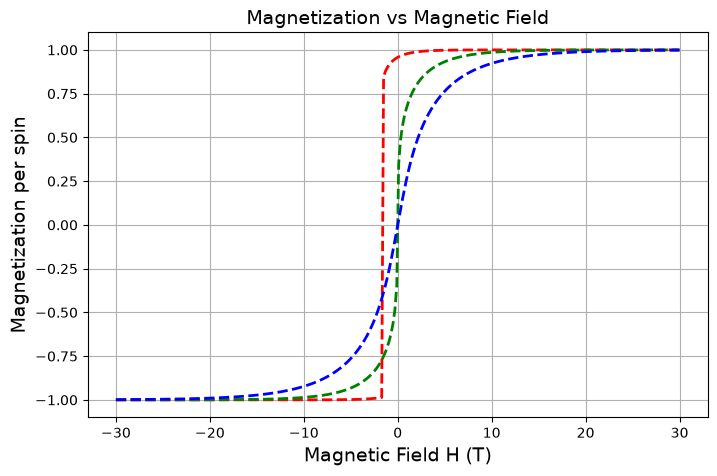

In [52]:
H_teorico = np.linspace(-30, 30, 300)
c_T1 = magnetizacion_curie_weiss(H_teorico, 5, 4)
c_T2 = magnetizacion_curie_weiss(H_teorico, 10, 4)
c_T3 = magnetizacion_curie_weiss(H_teorico, 15, 4)

plt.figure(figsize=(8,5))
plt.plot(H_teorico, c_T1, 'r--', lw=2, label='Curie-Weiss / Campo Medio (T=5 K)')
plt.plot(H_teorico, c_T2, 'g--', lw=2, label='Curie-Weiss / Campo Medio (T=10 K)')
plt.plot(H_teorico, c_T3, 'b--', lw=2, label='Curie-Weiss / Campo Medio (T=15 K)')
plt.title('Magnetization vs Magnetic Field',size=14)
plt.xlabel('Magnetic Field H (T)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.grid()
plt.show()

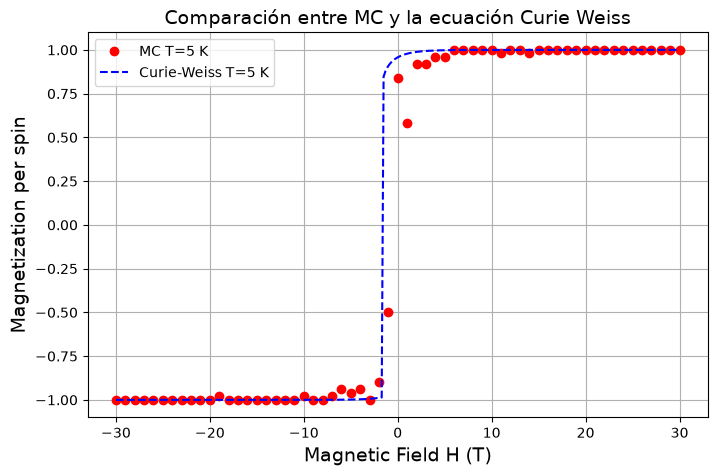

In [55]:
plt.figure(figsize=(8,5))
plt.plot(T1['H'], T1['Magnetization'], 'ro', label='MC T=5 K')
plt.plot(H_teorico, c_T1, 'b--', label='Curie-Weiss T=5 K')
plt.title('Comparación entre MC y la ecuación Curie Weiss',size=14)
plt.xlabel('Magnetic Field H (T)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.legend()
plt.grid()
plt.show()

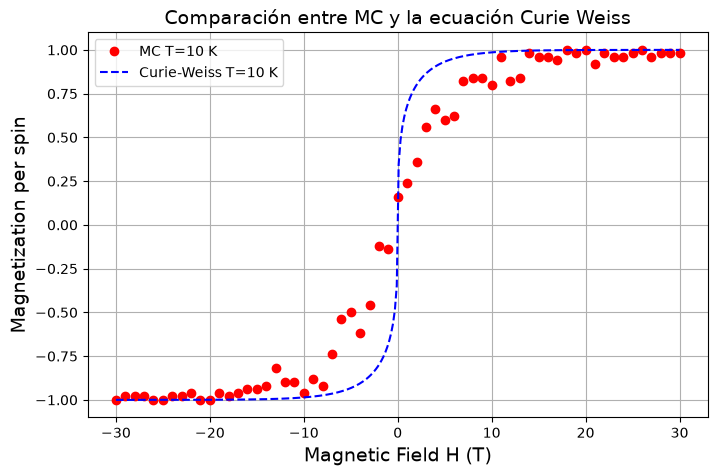

In [57]:
plt.figure(figsize=(8,5))
plt.plot(T2['H'], T2['Magnetization'], 'ro', label='MC T=10 K')
plt.plot(H_teorico, c_T2, 'b--', label='Curie-Weiss T=10 K')
plt.title('Comparación entre MC y la ecuación Curie Weiss',size=14)
plt.xlabel('Magnetic Field H (T)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.legend()
plt.grid()
plt.show()

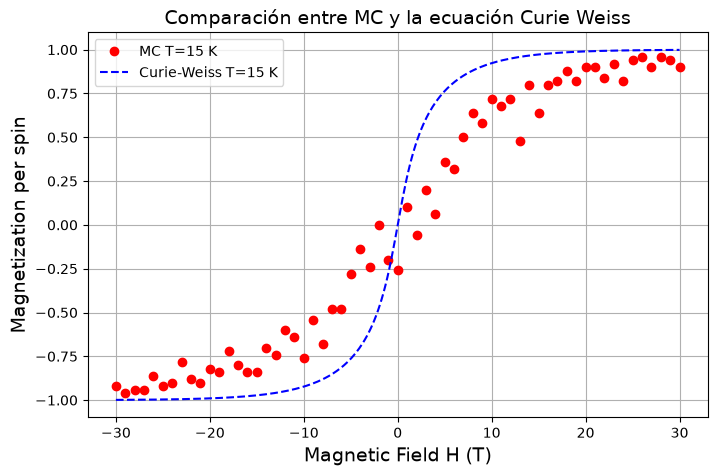

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(T3['H'], T3['Magnetization'], 'ro', label='MC T=15 K')
plt.plot(H_teorico, c_T3, 'b--', label='Curie-Weiss T=15 K')
plt.title('Comparación entre MC y la Ecuación Curie Weiss',size=14)
plt.xlabel('Magnetic Field H (T)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.legend()
plt.grid()
plt.show()